# Etapa 2. Reducción de dimensionalidad con PCA y reentrenamiento

## Entorno

Importé las librerías y fijé la semilla 42, que usan la partición y todos los modelos. Sin semilla,
K-Means y GMM arrancan desde centroides o componentes distintos en cada corrida, así que los grupos, su
numeración y las métricas cambiarían, y nadie podría verificar las cifras del informe. También imprimí
las versiones de Python, NumPy, pandas, scikit-learn y Matplotlib, porque los valores por defecto de los
estimadores cambian de una versión a otra y con ellos los resultados.

Definí tres funciones auxiliares. La función redondear aplica redondeo mitad hacia arriba una sola vez
sobre el valor completo. La usé en todas las cifras que se guardan porque round de Python trabaja sobre
la representación binaria y, por ejemplo, redondea 0,2175 a 0,217, mientras que el informe diría 0,218.
Así cada número se ve igual en el notebook y en el informe. La función guardar escribe la figura en
splits antes de mostrarla, porque plt.show libera la figura y el archivo saldría en blanco. La función
guardar_resultados agrega las cifras de cada notebook a resultados.json, de donde las toma el informe sin
copiarlas a mano.

In [1]:
import os, time, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib
from decimal import Decimal, ROUND_HALF_UP

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.dpi'] = 100
SEMILLA = 42
np.random.seed(SEMILLA)

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    if not os.path.isdir('/content/drive/MyDrive'):
        raise RuntimeError('Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso '
                           'en la ventana emergente.')
    RUTA = '/content/drive/MyDrive/credit_card'
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')

CARPETA_SPLITS = os.path.join(RUTA, 'splits')
os.makedirs(CARPETA_SPLITS, exist_ok=True)
ARCHIVO_RESULTADOS = os.path.join(RUTA, 'resultados.json')
resultados = {}
if os.path.exists(ARCHIVO_RESULTADOS):
    with open(ARCHIVO_RESULTADOS, encoding='utf-8') as f:
        resultados = json.load(f)

def redondear(valor, decimales=3):
    r = Decimal(repr(float(valor))).quantize(Decimal(1).scaleb(-decimales), rounding=ROUND_HALF_UP)
    return int(r) if decimales == 0 else float(r)

def redondear_serie(serie, decimales=3):
    return serie.map(lambda v: redondear(v, decimales))

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SPLITS, nombre + '.png'), dpi=150, bbox_inches='tight', facecolor='white')
    print('Gráfico guardado:', nombre + '.png')
    plt.show()

def guardar_resultados():
    with open(ARCHIVO_RESULTADOS, 'w', encoding='utf-8') as f:
        json.dump(resultados, f, ensure_ascii=False, indent=1,
                  default=lambda o: o.item() if hasattr(o, 'item') else str(o))
    print('Cifras guardadas en resultados.json')

resultados['versiones'] = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                           'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__}
print('Guardando en Google Drive' if EN_DRIVE else 'Google Drive no disponible, guardando localmente')
print('Versiones:', resultados['versiones'])

Google Drive no disponible, guardando localmente
Versiones: {'python': '3.12.10', 'numpy': '2.2.6', 'pandas': '3.0.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.9'}


## Carga de los datos preparados

Cargué de datos_preparados.joblib lo que dejó el notebook 03, las particiones de entrenamiento y prueba
en unidades originales y transformadas, las listas de columnas y la marca de atípicos. Usar ese archivo
en lugar de repetir el preprocesamiento garantiza que el transformador sea exactamente el que se ajustó
con entrenamiento. También cargué de etapa1.joblib los hiperparámetros y las etiquetas de los dos modelos
del notebook 04.

In [2]:
prep = joblib.load(os.path.join(RUTA, 'datos_preparados.joblib'))
X_train, X_test, X_tr, X_te = prep['X_train'], prep['X_test'], prep['X_tr'], prep['X_te']
MONTOS, RESTO, COLUMNAS, frecuencias, fuera = prep['MONTOS'], prep['RESTO'], prep['COLUMNAS'], prep['frecuencias'], prep['fuera']
print('Entrenamiento:', X_tr.shape, '| Prueba:', X_te.shape)

e1 = joblib.load(os.path.join(RUTA, 'etapa1.joblib'))
K_KM, COV, REG, K_GMM = e1['K_KM'], e1['COV'], e1['REG'], e1['K_GMM']
et_km_tr, et_km_te, et_gm_tr, et_gm_te = e1['et_km_tr'], e1['et_km_te'], e1['et_gm_tr'], e1['et_gm_te']
print('Etapa 1, K-Means con K =', K_KM, '| GMM', COV, 'reg_covar', REG, 'K =', K_GMM)

Entrenamiento: (7160, 17) | Prueba: (1790, 17)
Etapa 1, K-Means con K = 6 | GMM diag reg_covar 1.0 K = 6


## Funciones de ajuste y medición

Repetí sin cambios las funciones del notebook 04 que usan los dos modelos, para que se ajusten y se
evalúen con el mismo procedimiento. Si cada modelo tuviera su propio código de medición, una diferencia
en las métricas podría venir del código y no del modelo.

La función metricas calcula tres métricas internas de scikit-learn, que juzgan la partición solo con los
datos. Silhouette toma, para cada cliente, la distancia media a su propio grupo a(i) y la distancia media
al grupo vecino más cercano b(i), calcula s(i) = (b(i) − a(i)) / max(a(i), b(i)) y promedia sobre todos
los clientes. Va de menos 1 a 1 y mayor es mejor. Davies-Bouldin divide, para cada par de grupos, la suma
de sus dispersiones internas por la distancia entre sus centroides, se queda con el peor par de cada
grupo y promedia. Menor es mejor. Calinski-Harabasz es el cociente [tr(B) / (K − 1)] / [tr(W) / (n − K)]
entre la dispersión entre grupos y la dispersión dentro de ellos. Mayor es mejor, pero crece con el
número de clientes n, así que solo compara particiones del mismo conjunto.

La función estabilidad entrena el modelo en diez submuestras del 80 por ciento con semillas distintas y
compara cada partición con la del modelo entrenado con todos los clientes mediante el índice de Rand
ajustado, ARI = (RI − E[RI]) / (max(RI) − E[RI]). El ARI cuenta los pares de clientes que quedan juntos o
separados en las dos particiones y descuenta el acuerdo esperado al azar. Vale 1 si las particiones son
idénticas, cerca de 0 si coinciden como dos asignaciones aleatorias, y no depende del número que reciba
cada grupo. La función devuelve el ARI medio y el mínimo.

La función cronometrar repite cinco veces fit y predict y devuelve la mediana de cada tiempo, menos
sensible que la media a una medición interrumpida por otro proceso. Las funciones buscar_kmeans y
buscar_gmm recorren los hiperparámetros y aplican la regla que fijé antes de ver resultados, quedarse con
las configuraciones cuyo ARI mínimo entre submuestras sea de al menos 0,9 y elegir entre ellas la de
menor Davies-Bouldin. Puse la estabilidad primero porque un segmento que cambia cada vez que se reentrena
el modelo no sirve para una campaña comercial.

In [3]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

RANGO = range(2, 11)
COVS = ['full', 'tied', 'diag', 'spherical']
REGS = (1e-6, 1e-3, 1e-2, 1e-1, 0.3, 1.0)

def metricas(Z, etiquetas):
    return {'silhouette': redondear(silhouette_score(Z, etiquetas)),
            'davies_bouldin': redondear(davies_bouldin_score(Z, etiquetas)),
            'calinski_harabasz': redondear(calinski_harabasz_score(Z, etiquetas), 0)}

def estabilidad(fabrica, Z, repeticiones=10):
    referencia = fabrica(SEMILLA).fit(Z).predict(Z)
    gen = np.random.default_rng(SEMILLA)
    aris = []
    for s in range(repeticiones):
        idx = gen.choice(len(Z), int(0.8 * len(Z)), replace=False)
        modelo = fabrica(s).fit(Z[idx])
        aris.append(adjusted_rand_score(referencia, modelo.predict(Z)))
    return float(np.mean(aris)), float(np.min(aris))

def cronometrar(fabrica, Z_fit, Z_pred, repeticiones=5):
    t_fit, t_pred = [], []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        modelo = fabrica().fit(Z_fit)
        t_fit.append(time.perf_counter() - t0)
        t0 = time.perf_counter()
        modelo.predict(Z_pred)
        t_pred.append(time.perf_counter() - t0)
    return modelo, float(np.median(t_fit)), float(np.median(t_pred))

def gmm(k, cov, reg, semilla=SEMILLA):
    return GaussianMixture(n_components=k, covariance_type=cov, reg_covar=reg, n_init=5, random_state=semilla)

def codo_bic(bics, rango):
    mejoras = -np.diff(bics)
    for i in range(1, len(mejoras)):
        if mejoras[i] < 0.2 * mejoras[0]:
            return list(rango)[i]
    return list(rango)[-1]

def buscar_kmeans(Z, rango=RANGO):
    filas = []
    for k in rango:
        modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z)
        media, minimo = estabilidad(lambda s: KMeans(n_clusters=k, n_init=10, random_state=s), Z)
        filas.append({'K': k, 'inercia': redondear(modelo.inertia_, 0), **metricas(Z, modelo.labels_),
                      'estabilidad_media': redondear(media), 'estabilidad_min': redondear(minimo),
                      'grupo_menor': int(np.bincount(modelo.labels_).min())})
    tabla = pd.DataFrame(filas).set_index('K')
    estables = tabla[tabla['estabilidad_min'] >= 0.9]
    return tabla, int(estables['davies_bouldin'].idxmin())

def buscar_gmm(Z):
    filas, curvas = [], {}
    for cov in COVS:
        for reg in REGS:
            bics = [gmm(k, cov, reg).fit(Z).bic(Z) for k in RANGO]
            k = codo_bic(bics, RANGO)
            etiquetas = gmm(k, cov, reg).fit(Z).predict(Z)
            media, minimo = estabilidad(lambda s: gmm(k, cov, reg, s), Z)
            curvas[(cov, reg)] = bics
            filas.append({'covarianza': cov, 'reg_covar': reg, 'K_codo': k, **metricas(Z, etiquetas),
                          'estabilidad_media': redondear(media), 'estabilidad_min': redondear(minimo),
                          'grupo_menor': int(np.bincount(etiquetas, minlength=k).min())})
    tabla = pd.DataFrame(filas)
    estables = tabla[tabla['estabilidad_min'] >= 0.9]
    elegida = tabla.loc[estables['davies_bouldin'].idxmin()] if len(estables) else tabla.loc[tabla['estabilidad_min'].idxmax()]
    return tabla, curvas, elegida['covarianza'], float(elegida['reg_covar']), int(elegida['K_codo'])

def graficar_kmeans(tabla, k, nombre, titulo):
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    for a, col, et in zip(ax, ['inercia', 'silhouette', 'davies_bouldin', 'estabilidad_min'],
                          ['inercia (menor es mejor)', 'Silhouette (mayor es mejor)', 'Davies-Bouldin (menor es mejor)', 'ARI mínimo entre submuestras']):
        a.plot(tabla.index, tabla[col], 'o-', color='#2f6690')
        a.axvline(k, color='#d1495b', ls='--', label=f'K elegido = {k}')
        a.set_xlabel('K')
        a.set_ylabel(et)
        a.legend()
    ax[3].axhline(0.9, color='gray', ls=':')
    fig.suptitle(titulo)
    guardar(nombre)

def graficar_gmm(tabla, curvas, cov, reg, k, nombre, titulo):
    fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
    for r in REGS:
        ax[0].plot(list(RANGO), curvas[(cov, r)], 'o-', label=f'reg_covar = {r:g}')
    ax[0].set_xlabel('número de componentes')
    ax[0].set_ylabel('BIC (menor es mejor)')
    ax[0].set_title(f'BIC con covarianza {cov} según la regularización')
    ax[0].legend(fontsize=7)
    ax[1].plot(list(RANGO), curvas[(cov, reg)], 'o-', color='#2f6690')
    ax[1].axvline(k, color='#d1495b', ls='--', label=f'codo, K = {k}')
    ax[1].set_xlabel('número de componentes')
    ax[1].set_ylabel('BIC (menor es mejor)')
    ax[1].set_title(f'BIC con covarianza {cov} y reg_covar = {reg:g}')
    ax[1].legend()
    for c, g in tabla.groupby('covarianza'):
        ax[2].scatter(g['estabilidad_min'], g['davies_bouldin'], label=c, s=40)
    fila = tabla[(tabla['covarianza'] == cov) & (tabla['reg_covar'] == reg)].iloc[0]
    ax[2].scatter([fila['estabilidad_min']], [fila['davies_bouldin']], s=220, facecolors='none',
                  edgecolors='#d1495b', linewidths=2, label='elegida')
    ax[2].axvline(0.9, color='gray', ls=':')
    ax[2].set_xlabel('ARI mínimo entre submuestras')
    ax[2].set_ylabel('Davies-Bouldin (menor es mejor)')
    ax[2].set_title('Estabilidad y separación de cada combinación')
    ax[2].legend(fontsize=7)
    fig.suptitle(titulo)
    guardar(nombre)

## Aplicación de PCA

PCA busca direcciones ortogonales de máxima varianza. Sobre la matriz escalada de entrenamiento X calcula
la descomposición en valores singulares X = U S Vᵀ. Las filas de Vᵀ son las componentes, sus coeficientes
son las cargas de cada variable, y la varianza de la componente j es λ_j = s_j² / (n − 1). La proyección
Z = X V_k conserva las k primeras, y como esas componentes no están correlacionadas entre sí, se elimina
la redundancia que mostró el notebook 02.

Ajusté PCA solo con entrenamiento, grafiqué la varianza explicada y elegí k con el criterio que fijé
antes de mirar, retener al menos el 90 por ciento de la varianza. Después proyecté entrenamiento y prueba
con la misma matriz V_k. El 90 por ciento es el extremo inferior del rango que admite la consigna (90 a
95 por ciento). Lo elegí para quitar la mayor redundancia posible, y en la sección de sensibilidad
comprobé qué pasa con el 95.

Gráfico guardado: 05_pca_varianza.png


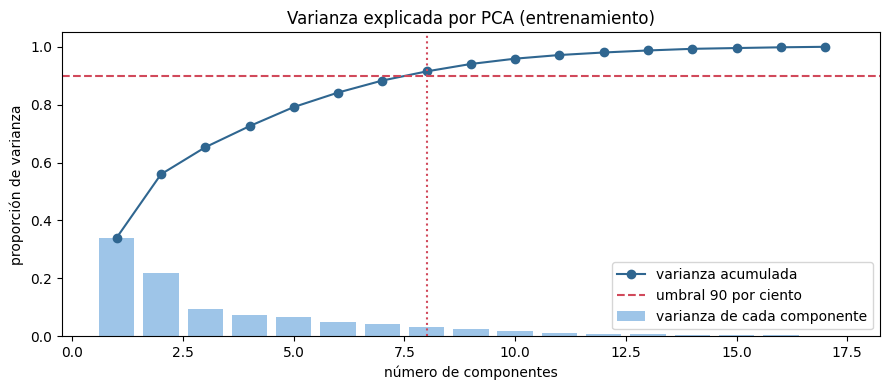

Componentes para 90 por ciento: 8 | para 95 por ciento: 10
Varianza retenida: 91.5 por ciento
Varianza de cada componente (por ciento): [34.0, 21.9, 9.3, 7.3, 6.6, 5.0, 4.2, 3.2]


In [4]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=SEMILLA).fit(X_tr)
acumulada = np.cumsum(pca_full.explained_variance_ratio_)
K_PCA = int(np.argmax(acumulada >= 0.90) + 1)
K_PCA95 = int(np.argmax(acumulada >= 0.95) + 1)
resultados['pca_acumulada'] = [redondear(v * 100, 1) for v in acumulada]
resultados['pca_varianza'] = [redondear(v * 100, 1) for v in pca_full.explained_variance_ratio_]
resultados['k_pca'], resultados['k_pca95'] = K_PCA, K_PCA95

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 18), pca_full.explained_variance_ratio_, color='#9ec5e8', label='varianza de cada componente')
ax.plot(range(1, 18), acumulada, 'o-', color='#2f6690', label='varianza acumulada')
ax.axhline(0.90, color='#d1495b', ls='--', label='umbral 90 por ciento')
ax.axvline(K_PCA, color='#d1495b', ls=':')
ax.set_xlabel('número de componentes')
ax.set_ylabel('proporción de varianza')
ax.set_title('Varianza explicada por PCA (entrenamiento)')
ax.legend()
guardar('05_pca_varianza')
print('Componentes para 90 por ciento:', K_PCA, '| para 95 por ciento:', K_PCA95)

pca = PCA(n_components=K_PCA, random_state=SEMILLA).fit(X_tr)
Z_tr, Z_te = pca.transform(X_tr), pca.transform(X_te)
resultados['var_retenida'] = redondear(pca.explained_variance_ratio_.sum() * 100, 1)
print('Varianza retenida:', resultados['var_retenida'], 'por ciento')
print('Varianza de cada componente (por ciento):', resultados['pca_varianza'][:K_PCA])

Con 8 componentes retuve el 91,5 por ciento de la varianza, por encima del 90 por ciento fijado. Para el
95 por ciento habrían hecho falta 10. Las dos primeras componentes explicaron juntas el 56,0 por ciento,
así que el espacio se redujo a menos de la mitad de dimensiones perdiendo menos de una décima parte de la
información.

Revisé las cargas de las tres primeras componentes para traducir cada una a una conducta del cliente,
porque una componente que no se puede interpretar tampoco ayuda a explicar los grupos al banco. El signo
de cada componente es arbitrario, así que importa el signo de una variable respecto de las otras y no el
signo absoluto.

Gráfico guardado: 05_pca_cargas.png


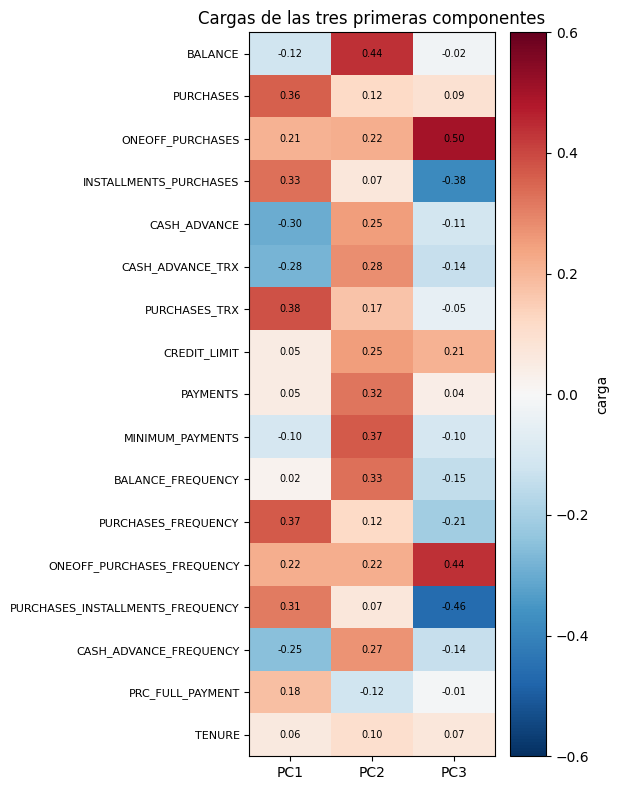

,PC1,PC2,PC3
CASH_ADVANCE,-0.30,0.25,-0.11
CASH_ADVANCE_TRX,-0.28,0.28,-0.14
CASH_ADVANCE_FREQUENCY,-0.25,0.27,-0.14
BALANCE,-0.12,0.44,-0.02
MINIMUM_PAYMENTS,-0.10,0.37,-0.10
BALANCE_FREQUENCY,0.02,0.33,-0.15
PAYMENTS,0.05,0.32,0.04
CREDIT_LIMIT,0.05,0.25,0.21
TENURE,0.06,0.10,0.07
PRC_FULL_PAYMENT,0.18,-0.12,-0.01


In [5]:
cargas = pd.DataFrame(pca.components_[:3].T, index=COLUMNAS, columns=['PC1', 'PC2', 'PC3']).apply(lambda c: redondear_serie(c, 2))
resultados['cargas'] = cargas.to_dict()
fig, ax = plt.subplots(figsize=(6, 8))
im = ax.imshow(cargas, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
ax.set_xticks(range(3))
ax.set_xticklabels(cargas.columns)
ax.set_yticks(range(len(cargas)))
ax.set_yticklabels(cargas.index, fontsize=8)
for i in range(len(cargas)):
    for j in range(3):
        ax.text(j, i, f'{cargas.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, label='carga')
ax.set_title('Cargas de las tres primeras componentes')
guardar('05_pca_cargas')
cargas.sort_values('PC1')

PC1 (34,0 por ciento de la varianza) tuvo cargas positivas en las compras y su frecuencia (PURCHASES_TRX
0,38, PURCHASES_FREQUENCY 0,37, PURCHASES 0,36, INSTALLMENTS_PURCHASES 0,33) y negativas en los avances
en efectivo (CASH_ADVANCE menos 0,30, CASH_ADVANCE_TRX menos 0,28). En términos del banco, PC1 mide si el
cliente usa la tarjeta para comprar o para sacar efectivo. PC2 (21,9 por ciento) tuvo todas sus cargas
importantes positivas, en el saldo (0,44), el pago mínimo (0,37), los pagos (0,32) y la frecuencia del
saldo (0,33), así que mide el nivel de deuda y movimiento de la cuenta. PC3 separó la compra en un solo
pago (ONEOFF_PURCHASES 0,50) de la compra en cuotas (INSTALLMENTS_PURCHASES menos 0,38).

## Visualización en dos dimensiones y t-SNE

Proyecté los clientes de entrenamiento sobre PC1 y PC2, coloreados por las particiones de la etapa 1, y
para comparar apliqué t-SNE a una submuestra de 3 000 clientes. t-SNE convierte las distancias en
probabilidades de ser vecinos con un núcleo gaussiano cuyo ancho se ajusta en cada punto según la
perplejidad. Usé 30, del orden del número de vecinos efectivos. Después ubica los puntos en dos
dimensiones de modo que sus probabilidades, calculadas con una t de Student, se parezcan a las
originales, y para eso minimiza la divergencia de Kullback-Leibler. Lo usé solo para mirar. scikit-learn
no ofrece transform para ubicar puntos nuevos con t-SNE, así que no podría asignar clientes de prueba.

Gráfico guardado: 05_pca_tsne.png


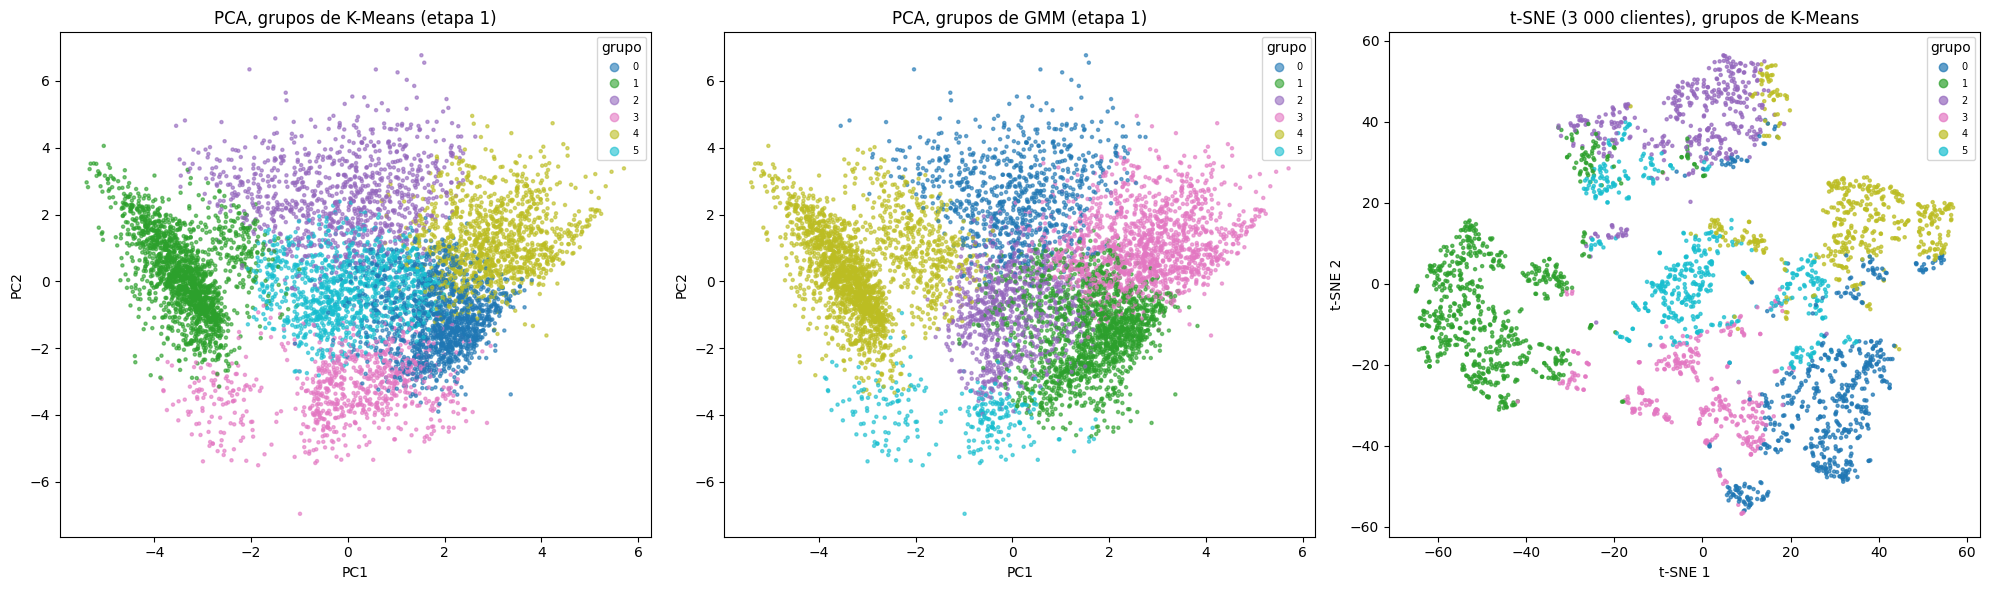

Tiempo de t-SNE: 35.7 segundos


In [6]:
from sklearn.manifold import TSNE

gen = np.random.default_rng(SEMILLA)
muestra = gen.choice(len(X_tr), 3000, replace=False)
t0 = time.perf_counter()
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEMILLA).fit_transform(X_tr[muestra])
resultados['t_tsne'] = redondear(time.perf_counter() - t0, 1)
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
for a, et, t in zip(ax[:2], [et_km_tr, et_gm_tr], ['K-Means', 'GMM']):
    sc = a.scatter(Z_tr[:, 0], Z_tr[:, 1], c=et, cmap='tab10', s=5, alpha=0.6)
    a.set_xlabel('PC1')
    a.set_ylabel('PC2')
    a.set_title(f'PCA, grupos de {t} (etapa 1)')
    a.legend(*sc.legend_elements(), title='grupo', fontsize=7)
sc = ax[2].scatter(tsne[:, 0], tsne[:, 1], c=et_km_tr[muestra], cmap='tab10', s=5, alpha=0.7)
ax[2].set_xlabel('t-SNE 1')
ax[2].set_ylabel('t-SNE 2')
ax[2].set_title('t-SNE (3 000 clientes), grupos de K-Means')
ax[2].legend(*sc.legend_elements(), title='grupo', fontsize=7)
guardar('05_pca_tsne')
print('Tiempo de t-SNE:', resultados['t_tsne'], 'segundos')

En PCA los grupos se ven como zonas contiguas que se tocan en los bordes, mientras que t-SNE los muestra
como islas bien separadas. t-SNE preserva los vecindarios locales pero no las distancias globales ni el
tamaño de los grupos, así que de esa figura se puede concluir que los clientes de un mismo grupo son
vecinos entre sí, pero no que los grupos estén lejos unos de otros ni que tengan la forma o el tamaño que
aparentan. No lo usé como entrada de un modelo porque el resultado depende de la perplejidad y de la
semilla, no tiene un método para proyectar clientes nuevos y fabrica separaciones que no existen en los
datos originales. Con solo 3 000 clientes tardó muchas veces más que cualquiera de los dos modelos con
los 7 160 clientes de entrenamiento.

## Reajuste en el espacio reducido

Repetí sobre las componentes principales exactamente la misma búsqueda del notebook 04, con las mismas
funciones y la misma regla de decisión. Así el número de grupos, el tipo de covarianza y la
regularización pueden cambiar si el nuevo espacio lo pide, pero no porque cambie el criterio.

Gráfico guardado: 05_kmeans_seleccion_pca.png


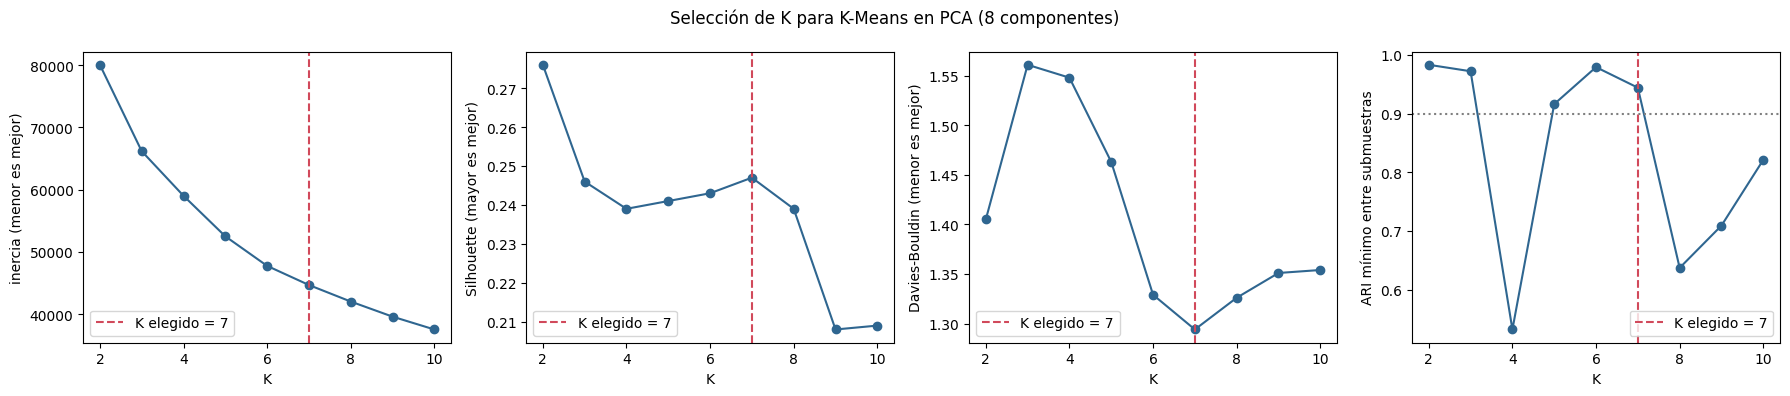

Gráfico guardado: 05_gmm_seleccion_pca.png


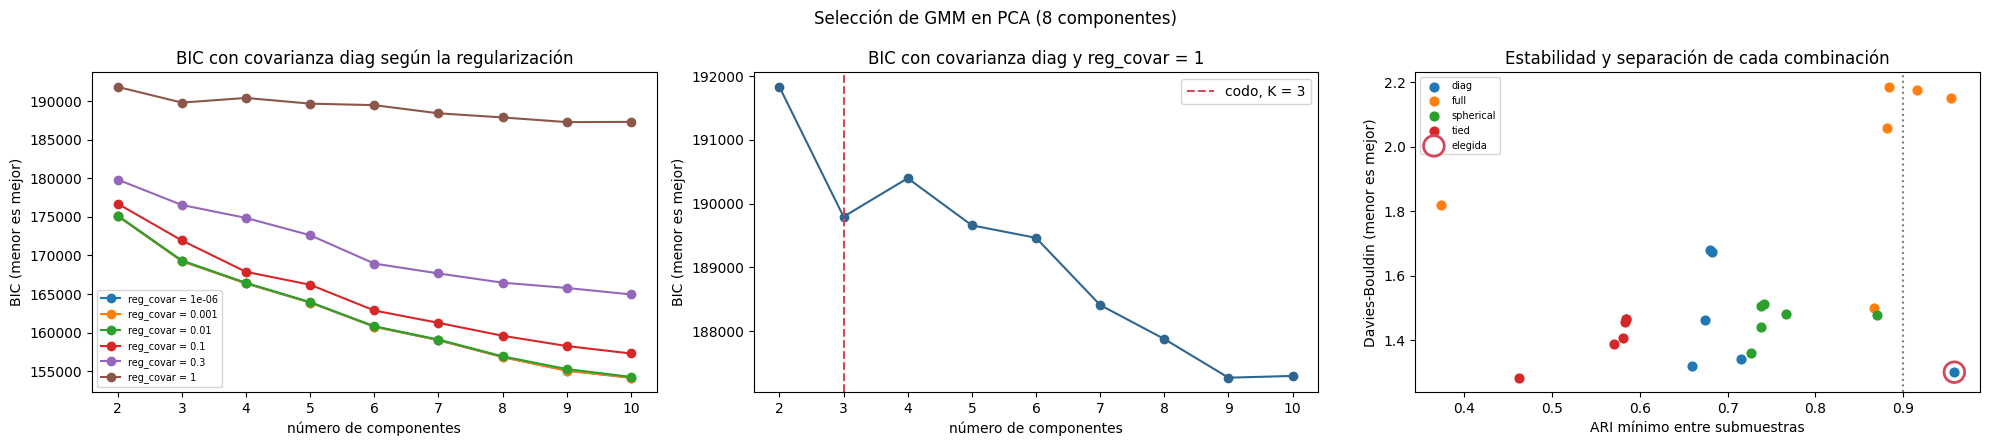

K-Means en PCA, K = 7 | GMM en PCA: diag reg_covar 1.0 K = 3


,inercia,silhouette,davies_bouldin,calinski_harabasz,estabilidad_media,estabilidad_min,grupo_menor
K,,,,,,,
2,80075,0.276,1.405,2798,0.989,0.983,2553
3,66189,0.246,1.561,2443,0.983,0.972,2311
4,59014,0.239,1.548,2117,0.927,0.532,1256
5,52500,0.241,1.463,2006,0.970,0.916,1029
6,47744,0.243,1.329,1907,0.985,0.979,807
7,44668,0.247,1.294,1780,0.975,0.944,402
8,42008,0.239,1.326,1687,0.927,0.637,345
9,39582,0.208,1.351,1621,0.924,0.709,345
10,37517,0.209,1.354,1564,0.941,0.821,337


,covarianza,reg_covar,K_codo,silhouette,davies_bouldin,calinski_harabasz,estabilidad_media,estabilidad_min,grupo_menor
0,full,0.000001,4,0.152,2.185,1274,0.954,0.884,1329
1,full,0.001000,4,0.166,2.174,1336,0.970,0.916,1262
2,full,0.010000,4,0.155,2.152,1296,0.977,0.954,1321
3,full,0.100000,4,0.174,2.057,1429,0.957,0.881,921
4,full,0.300000,4,0.197,1.819,1528,0.871,0.374,623
5,full,1.000000,4,0.227,1.499,1581,0.958,0.867,292
6,tied,0.000001,9,0.214,1.466,1272,0.740,0.584,172
7,tied,0.001000,9,0.214,1.466,1273,0.740,0.584,172
8,tied,0.010000,9,0.215,1.457,1279,0.745,0.583,173
9,tied,0.100000,9,0.215,1.406,1324,0.779,0.581,172


In [7]:
tabla_km_pca, K_KM_PCA = buscar_kmeans(Z_tr)
graficar_kmeans(tabla_km_pca, K_KM_PCA, '05_kmeans_seleccion_pca', f'Selección de K para K-Means en PCA ({K_PCA} componentes)')
tabla_gmm_pca, curvas_pca, COV_PCA, REG_PCA, K_GMM_PCA = buscar_gmm(Z_tr)
graficar_gmm(tabla_gmm_pca, curvas_pca, COV_PCA, REG_PCA, K_GMM_PCA, '05_gmm_seleccion_pca', f'Selección de GMM en PCA ({K_PCA} componentes)')
resultados['tabla_km_pca'] = tabla_km_pca.reset_index().to_dict(orient='list')
resultados['tabla_gmm_pca'] = tabla_gmm_pca.to_dict(orient='list')
resultados['k_km_pca'], resultados['cov_pca'], resultados['reg_pca'], resultados['k_gmm_pca'] = K_KM_PCA, COV_PCA, REG_PCA, K_GMM_PCA
print('K-Means en PCA, K =', K_KM_PCA, '| GMM en PCA:', COV_PCA, 'reg_covar', REG_PCA, 'K =', K_GMM_PCA)
display(tabla_km_pca)
tabla_gmm_pca

En el espacio reducido K-Means volvió a aplicar la misma regla y eligió K igual a 7, que ahora sí fue
estable (estabilidad mínima de 0,944), con un Davies-Bouldin de 1,294. En GMM la regla eligió otra vez la
covarianza diag con reg_covar igual a 1, ahora con solo 3 componentes. Con 8 componentes no
correlacionadas el codo del BIC llegó antes. Casi todas las combinaciones con más componentes fueron
inestables, con estabilidades mínimas por debajo de 0,9. Las únicas estables con más componentes fueron
las de covarianza full con reg_covar de 0,001 y 0,01 (4 componentes y estabilidad mínima de 0,916 y
0,954), pero la regla las descartó porque su Davies-Bouldin fue mucho mayor, de 2,174 y 2,152 contra
1,301.

## Tabla comparativa

Entrené los dos modelos finales en el espacio reducido y armé la tabla de los cuatro modelos, dos
algoritmos por dos espacios. En cada fila las métricas se calculan en el espacio donde se entrenó el
modelo. El ARI contra el original compara la partición de cada modelo en PCA con la del mismo algoritmo
en la etapa 1, sobre los mismos clientes.

Las métricas de un espacio de 8 dimensiones no se pueden comparar directamente con las de uno de 17,
porque las distancias no son las mismas. Por eso agregué las filas de comparación justa, que toman las
etiquetas obtenidas en PCA y calculan las métricas en el espacio original escalado, el mismo donde se
midieron los modelos de la etapa 1.

In [8]:
fab_km = lambda: KMeans(n_clusters=K_KM, n_init=10, random_state=SEMILLA)
fab_gmm = lambda: gmm(K_GMM, COV, REG)
fab_km_pca = lambda: KMeans(n_clusters=K_KM_PCA, n_init=10, random_state=SEMILLA)
fab_gmm_pca = lambda: gmm(K_GMM_PCA, COV_PCA, REG_PCA)
t_km, tp_km, t_gm, tp_gm = e1['t_km'], e1['tp_km'], e1['t_gm'], e1['tp_gm']
km_p, t_km_p, tp_km_p = cronometrar(fab_km_pca, Z_tr, Z_te)
gm_p, t_gm_p, tp_gm_p = cronometrar(fab_gmm_pca, Z_tr, Z_te)
et_kmp_tr, et_kmp_te = km_p.predict(Z_tr), km_p.predict(Z_te)
et_gmp_tr, et_gmp_te = gm_p.predict(Z_tr), gm_p.predict(Z_te)

def fila(modelo, espacio, hiper, k, Z_a, e_a, Z_b, e_b, t_fit, t_pred, ari_tr, ari_te):
    a, b = metricas(Z_a, e_a), metricas(Z_b, e_b)
    return {'Modelo': modelo, 'Espacio': espacio, 'Hiperparámetros': hiper, 'N.° grupos': k,
            'Silhouette (entr.)': a['silhouette'], 'Silhouette (prueba)': b['silhouette'],
            'Davies-Bouldin (entr.)': a['davies_bouldin'], 'Davies-Bouldin (prueba)': b['davies_bouldin'],
            'Calinski-Harabasz (entr.)': a['calinski_harabasz'], 'Calinski-Harabasz (prueba)': b['calinski_harabasz'],
            '% ruido': 'No aplica', 'Tiempo entrenamiento (s)': redondear(t_fit, 3), 'Tiempo predicción (s)': redondear(t_pred, 4),
            'ARI vs. original (entr.)': ari_tr, 'ARI vs. original (prueba)': ari_te}

ari_km_tr, ari_km_te = redondear(adjusted_rand_score(et_km_tr, et_kmp_tr)), redondear(adjusted_rand_score(et_km_te, et_kmp_te))
ari_gm_tr, ari_gm_te = redondear(adjusted_rand_score(et_gm_tr, et_gmp_tr)), redondear(adjusted_rand_score(et_gm_te, et_gmp_te))
h_km = lambda k: f'K = {k}, n_init = 10'
h_gm = lambda k, c, r: f'K = {k}, covarianza {c}, reg_covar = {r:g}, n_init = 5'
tabla = pd.DataFrame([
    fila('A: K-Means', 'Original (17 variables)', h_km(K_KM), K_KM, X_tr, et_km_tr, X_te, et_km_te, t_km, tp_km, '—', '—'),
    fila('A: K-Means', f'PCA ({K_PCA} comp.)', h_km(K_KM_PCA), K_KM_PCA, Z_tr, et_kmp_tr, Z_te, et_kmp_te, t_km_p, tp_km_p, ari_km_tr, ari_km_te),
    fila('B: GMM', 'Original (17 variables)', h_gm(K_GMM, COV, REG), K_GMM, X_tr, et_gm_tr, X_te, et_gm_te, t_gm, tp_gm, '—', '—'),
    fila('B: GMM', f'PCA ({K_PCA} comp.)', h_gm(K_GMM_PCA, COV_PCA, REG_PCA), K_GMM_PCA, Z_tr, et_gmp_tr, Z_te, et_gmp_te, t_gm_p, tp_gm_p, ari_gm_tr, ari_gm_te)])
justa = pd.DataFrame([
    fila('A: K-Means', f'PCA ({K_PCA} comp.), métricas en el original', h_km(K_KM_PCA), K_KM_PCA, X_tr, et_kmp_tr, X_te, et_kmp_te, t_km_p, tp_km_p, ari_km_tr, ari_km_te),
    fila('B: GMM', f'PCA ({K_PCA} comp.), métricas en el original', h_gm(K_GMM_PCA, COV_PCA, REG_PCA), K_GMM_PCA, X_tr, et_gmp_tr, X_te, et_gmp_te, t_gm_p, tp_gm_p, ari_gm_tr, ari_gm_te)])
resultados['tabla_comparativa'] = tabla.to_dict(orient='records')
resultados['tabla_justa'] = justa.to_dict(orient='records')
display(tabla.T)
justa.T

,0,1,2,3
Modelo,A: K-Means,A: K-Means,B: GMM,B: GMM
Espacio,Original (17 variables),PCA (8 comp.),Original (17 variables),PCA (8 comp.)
Hiperparámetros,"K = 6, n_init = 10","K = 7, n_init = 10","K = 6, covarianza diag, reg_covar = 1, n_init = 5","K = 3, covarianza diag, reg_covar = 1, n_init = 5"
N.° grupos,6,7,6,3
Silhouette (entr.),0.218,0.247,0.213,0.265
Silhouette (prueba),0.218,0.247,0.213,0.26
Davies-Bouldin (entr.),1.469,1.294,1.528,1.301
Davies-Bouldin (prueba),1.459,1.303,1.547,1.321
Calinski-Harabasz (entr.),1607,1780,1475,1745
Calinski-Harabasz (prueba),408,450,374,424


,0,1
Modelo,A: K-Means,B: GMM
Espacio,"PCA (8 comp.), métricas en el original","PCA (8 comp.), métricas en el original"
Hiperparámetros,"K = 7, n_init = 10","K = 3, covarianza diag, reg_covar = 1, n_init = 5"
N.° grupos,7,3
Silhouette (entr.),0.221,0.246
Silhouette (prueba),0.222,0.241
Davies-Bouldin (entr.),1.416,1.396
Davies-Bouldin (prueba),1.422,1.424
Calinski-Harabasz (entr.),1478,1544
Calinski-Harabasz (prueba),372,375


Medidas en su propio espacio, las métricas de los dos modelos mejoraron con PCA. K-Means pasó de un
Silhouette de 0,218 a 0,247 y de un Davies-Bouldin de 1,469 a 1,294. GMM pasó de 0,213 a 0,265 y de 1,528
a 1,301.

Esas cifras no se pueden comparar directamente, porque las distancias en 8 componentes no son las mismas
que en 17 variables. Al quitar las componentes de menor varianza, que en buena parte son ruido y
redundancia, los puntos de un mismo grupo quedan más cerca y casi cualquier partición se ve mejor. En la
comparación justa la mejora de K-Means se achicó pero se mantuvo (Silhouette de 0,221 contra 0,218 y
Davies-Bouldin de 1,416 contra 1,469). La de GMM también se mantuvo y fue mayor (Silhouette de 0,246
contra 0,213 y Davies-Bouldin de 1,396 contra 1,528), así que GMM sobre PCA tuvo las mejores métricas de
los cuatro modelos.

Esa ventaja tiene una explicación que no es la calidad del modelo. GMM en PCA tiene 3 grupos y K-Means
tiene 7, y Silhouette tiende a favorecer particiones con pocos grupos grandes, como ya se vio en K-Means,
donde K igual a 2 tuvo el mejor Silhouette. A igual número de grupos la comparación es más pareja.
K-Means con K igual a 3 en PCA tuvo un Silhouette de 0,246 en su propio espacio, contra 0,265 de GMM.

### Estabilidad y cambio en las asignaciones

Medí la estabilidad de los dos modelos del espacio reducido y crucé sus grupos con los de la etapa 1,
para ver qué clientes cambiaron de grupo. Una mejora en las métricas no sirve si la partición deja de ser
estable, y el cruce muestra si PCA reordenó a los clientes o solo ajustó los bordes.

In [9]:
est_km_p = estabilidad(lambda s: KMeans(n_clusters=K_KM_PCA, n_init=10, random_state=s), Z_tr)
est_gm_p = estabilidad(lambda s: gmm(K_GMM_PCA, COV_PCA, REG_PCA, s), Z_tr)
resultados['estabilidad_pca'] = {'K-Means': [redondear(v) for v in est_km_p], 'GMM': [redondear(v) for v in est_gm_p]}
cruce = pd.crosstab(pd.Series(et_km_tr, name='K-Means original'), pd.Series(et_kmp_tr, name='K-Means PCA'))
resultados['cruce_km'] = cruce.values.tolist()
cruce_g = pd.crosstab(pd.Series(et_gm_tr, name='GMM original'), pd.Series(et_gmp_tr, name='GMM PCA'))
resultados['cruce_gmm'] = cruce_g.values.tolist()
print('Estabilidad en PCA (ARI medio y mínimo entre submuestras):', resultados['estabilidad_pca'])
display(cruce)
cruce_g

Estabilidad en PCA (ARI medio y mínimo entre submuestras): {'K-Means': [0.975, 0.944], 'GMM': [0.981, 0.958]}


K-Means PCA,0,1,2,3,4,5,6
K-Means original,,,,,,,
0,1242,0,15,0,85,0,11
1,0,1627,2,0,133,0,0
2,22,34,0,860,44,14,1
3,0,0,736,0,66,0,0
4,24,0,1,22,5,55,1059
5,41,17,23,0,69,950,2


GMM PCA,0,1,2
GMM original,,,
0,1,118,714
1,44,4,1636
2,19,71,770
3,0,0,1449
4,0,2038,21
5,193,49,33


Los dos modelos siguieron siendo estables en el espacio reducido, con un ARI mínimo entre submuestras de
0,944 para K-Means y de 0,958 para GMM. Las particiones cambiaron poco en K-Means, con un ARI de 0,838
entre la original y la reducida. La tabla cruzada muestra que cada uno de los seis grupos originales pasó
en su gran mayoría a un mismo grupo en PCA, y que el séptimo grupo nuevo se formó con 402 clientes de
borde tomados de todos los demás. En GMM el ARI fue de 0,346 porque los seis grupos se redujeron a tres.
Los usuarios de efectivo quedaron casi enteros en un grupo y los inactivos en otro, pero los compradores
premium, en cuotas y ocasionales quedaron fusionados en un solo grupo junto con los intensivos
endeudados.

La reducción ayudó a los dos modelos porque con 17 variables, varias casi copias de otras, la distancia
contaba varias veces la misma información y las diferencias entre clientes se diluían. PCA quitó esa
redundancia y el ruido de las últimas componentes. Como las componentes no están correlacionadas, la
covarianza diag de GMM dejó de ser una simplificación y pasó a describir bien la forma de los datos.

## Sensibilidad al número de componentes

El criterio admite retener entre el 90 y el 95 por ciento de la varianza. Repetí la búsqueda de K-Means
con las componentes necesarias para el 95 por ciento y comparé las métricas en el espacio original, para
ver si el resultado dependía de haber elegido el extremo inferior.

In [10]:
pca95 = PCA(n_components=K_PCA95, random_state=SEMILLA).fit(X_tr)
Z95 = pca95.transform(X_tr)
tabla_km95, K_KM95 = buscar_kmeans(Z95)
km95 = KMeans(n_clusters=K_KM95, n_init=10, random_state=SEMILLA).fit(Z95)
sensibilidad = pd.DataFrame([
    {'componentes': K_PCA, 'varianza': redondear(pca.explained_variance_ratio_.sum() * 100, 1), 'K': K_KM_PCA,
     **metricas(X_tr, et_kmp_tr), 'ARI vs. original': redondear(adjusted_rand_score(et_km_tr, et_kmp_tr))},
    {'componentes': K_PCA95, 'varianza': redondear(pca95.explained_variance_ratio_.sum() * 100, 1), 'K': K_KM95,
     **metricas(X_tr, km95.labels_), 'ARI vs. original': redondear(adjusted_rand_score(et_km_tr, km95.labels_))}]).set_index('componentes')
resultados['sensibilidad_pca'] = sensibilidad.reset_index().to_dict(orient='records')
sensibilidad

,varianza,K,silhouette,davies_bouldin,calinski_harabasz,ARI vs. original
componentes,,,,,,
8,91.5,7,0.221,1.416,1478,0.838
10,95.9,7,0.219,1.418,1480,0.878


Con 10 componentes, que retienen el 95,9 por ciento de la varianza, K-Means eligió el mismo K igual a 7 y
obtuvo prácticamente las mismas métricas en el espacio original (Silhouette de 0,219 contra 0,221 y
Davies-Bouldin de 1,418 contra 1,416). La conclusión no depende de haber elegido 8 componentes, y con 8
se logra lo mismo con dos dimensiones menos.

## Costo computacional y escalabilidad

En K-Means cada iteración cuesta del orden de n·K·d. En GMM con covarianza diag también crece con n·K·d,
pero cada término exige evaluar una densidad normal y normalizar responsabilidades con exponenciales y
logaritmos, y EM suele necesitar más iteraciones que Lloyd. Con covarianza full el costo subiría a n·K·d²
más la inversión de K matrices de d × d. PCA baja d de 17 a 8 en los dos modelos.

Con 7 160 clientes los tiempos son tan cortos que los domina el costo fijo de arrancar cada modelo. Para
ver cómo crecen armé conjuntos de 1, 2, 4 y 8 veces el entrenamiento, replicando a los clientes con un
ruido gaussiano pequeño (desvío 0,05 en unidades estandarizadas) para que no fueran copias exactas. Medí
el tiempo de entrenamiento de cada modelo en cada tamaño con los mismos hiperparámetros y ajusté la recta
log t = a + b log n. La pendiente b es el exponente de crecimiento, 1 si el tiempo crece en proporción al
tamaño. Con esa recta extrapolé a un conjunto 100 veces más grande. Es una estimación y supone que el
número de iteraciones no cambia con el tamaño.

In [11]:
multiplos = [1, 2, 4, 8]
gen = np.random.default_rng(SEMILLA)
filas = []
for nombre, fab, Z in [('K-Means original', fab_km, X_tr), ('K-Means PCA', fab_km_pca, Z_tr),
                       ('GMM original', fab_gmm, X_tr), ('GMM PCA', fab_gmm_pca, Z_tr)]:
    tiempos = []
    for m in multiplos:
        grande = np.tile(Z, (m, 1)) + gen.normal(0, 0.05, (m * len(Z), Z.shape[1]))
        tiempos.append(cronometrar(fab, grande, grande, 3)[1])
    n = np.array(multiplos) * len(Z)
    pendiente, intercepto = np.polyfit(np.log(n), np.log(tiempos), 1)
    estimado = float(np.exp(intercepto + pendiente * np.log(100 * len(Z))))
    filas.append({'modelo': nombre, **{f't_{m}x': redondear(t, 3) for m, t in zip(multiplos, tiempos)},
                  'exponente': redondear(pendiente, 2), 'estimado_100x_s': redondear(estimado, 1)})
escala = pd.DataFrame(filas).set_index('modelo')
resultados['escalabilidad'] = escala.reset_index().to_dict(orient='records')
escala

,t_1x,t_2x,t_4x,t_8x,exponente,estimado_100x_s
modelo,,,,,,
K-Means original,0.625,0.708,1.108,2.306,0.63,9.7
K-Means PCA,0.581,0.546,0.942,1.878,0.59,7.0
GMM original,1.135,1.819,4.142,5.594,0.81,47.1
GMM PCA,0.429,0.622,1.070,1.881,0.72,11.1


Con el tamaño real todos los modelos entrenaron en pocos segundos o menos y asignaron a los 1 790
clientes de prueba en milésimas de segundo, así que el costo no decide nada a esta escala. PCA redujo el
tiempo de entrenamiento de los dos modelos, y sobre todo el de GMM, porque cada iteración trabaja con 8
dimensiones en lugar de 17 y, en el caso de GMM, con menos componentes. Los tiempos tan cortos varían de
una medición a otra, por eso para comparar el crecimiento usé esta tabla de tamaños crecientes.

La diferencia aparece al crecer. El tiempo de K-Means creció menos que proporcionalmente al tamaño en el
rango medido (exponentes de 0,63 y 0,59), y la extrapolación a 100 veces más clientes (716 000) quedó en
9,7 segundos en el espacio original y 7,0 en PCA. El de GMM creció más rápido (exponentes de 0,81 y 0,72)
y la extrapolación quedó en 47,1 segundos en el espacio original y 11,1 en PCA, porque en cada iteración
recalcula la probabilidad de cada cliente en cada componente. Para la cartera completa de un banco
grande, cualquiera de los dos sobre PCA podría reentrenarse cada mes sin infraestructura especial.

## Cierre del notebook

Guardé en etapa2.joblib las etiquetas de los modelos del espacio reducido, que usa el notebook 06.

In [12]:
joblib.dump({'K_PCA': K_PCA, 'K_KM_PCA': K_KM_PCA, 'COV_PCA': COV_PCA, 'REG_PCA': REG_PCA, 'K_GMM_PCA': K_GMM_PCA,
             'et_kmp_tr': et_kmp_tr, 'et_kmp_te': et_kmp_te, 'et_gmp_tr': et_gmp_tr, 'et_gmp_te': et_gmp_te},
            os.path.join(RUTA, 'etapa2.joblib'))
print('Particiones de la etapa 2 guardadas en etapa2.joblib')
guardar_resultados()

Particiones de la etapa 2 guardadas en etapa2.joblib
Cifras guardadas en resultados.json
